In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib

import peakweather

print(peakweather.__version__)

from peakweather import PeakWeatherDataset

0.2.2


In [22]:
dataset = PeakWeatherDataset(
    freq="h",
    aggregation_methods={"temperature": "mean", "wind_gust": "max"},
    extended_nwp_pars=["temperature", "wind_u", "wind_v"],
    compute_uv=True,
)

df, mask = dataset.get_observations(
    stations=["ABO", "GRO", "KLO"],  # list of stations
    parameters=["temperature", "wind_speed", "humidity"],  # list of weather parameters
    first_date="2024-08-02 16:32",
    last_date="2024-08-06 23:26",
    return_mask=True,
)

df.head()

temperature.zarr.zip: 1.28GB [00:36, 35.2MB/s]                               
wind_u.zarr.zip: 1.69GB [00:40, 42.0MB/s]                               
wind_v.zarr.zip: 1.70GB [00:52, 32.4MB/s]                               


nat_abbr                          ABO                               GRO  \
name                      temperature wind_speed   humidity temperature   
datetime                                                                  
2024-08-02 17:00:00+00:00   19.366667   2.600000  71.199997   24.050001   
2024-08-02 18:00:00+00:00   18.833334   1.100000  74.900002   22.566666   
2024-08-02 19:00:00+00:00   18.250000   0.900000  74.900002   21.400000   
2024-08-02 20:00:00+00:00   16.666666   1.350000  96.099998   21.666666   
2024-08-02 21:00:00+00:00   15.583333   1.166667  95.099998   21.750000   

nat_abbr                                                KLO             \
name                      wind_speed   humidity temperature wind_speed   
datetime                                                                 
2024-08-02 17:00:00+00:00   1.116667  80.800003   26.233332   2.450000   
2024-08-02 18:00:00+00:00   1.700000  85.000000   24.666666   2.833333   
2024-08-02 19:00:00+00:00   0.933333  85.300003   21.250000   2.683333   
2024-08-02 20:00:00+00:00   1.433333  88.199997   20.350000   3.233333   
2024-08-02 21:00:00+00:00   1.366667  80.400002   19.600000   2.450000   

nat_abbr                              
name                        humidity  
datetime                              
2024-08-02 17:00:00+00:00  55.799999  
2024-08-02 18:00:00+00:00  59.000000  
2024-08-02 19:00:00+00:00  87.500000  
2024-08-02 20:00:00+00:00  94.599998  
2024-08-02 21:00:00+00:00  92.500000

In [15]:
def plot_weather_parameters(df, stations, parameters):
    fig, ax = plt.subplots(len(parameters), figsize=(12, 7))

    time_freq = mdates.date2num(df.index[1]) - mdates.date2num(df.index[0])
    time_freq_minutes = int(time_freq * 24 * 60)

    colors = matplotlib.colormaps["tab10"]

    for i, param in enumerate(parameters):
        for station in stations:
            ax[i].plot(
                df.index,
                df[station, param],
                label=f"{station} {param}",
                color=colors(stations.index(station)),
            )
        ax[i].set_title(f"{param.capitalize()} ({time_freq_minutes} min)")
        ax[i].set_ylabel(f"{param.capitalize()} ({dataset.parameters_table['unit'][param]})")
        ax[i].legend()
        ax[i].grid(True)

    plt.tight_layout()
    plt.show()

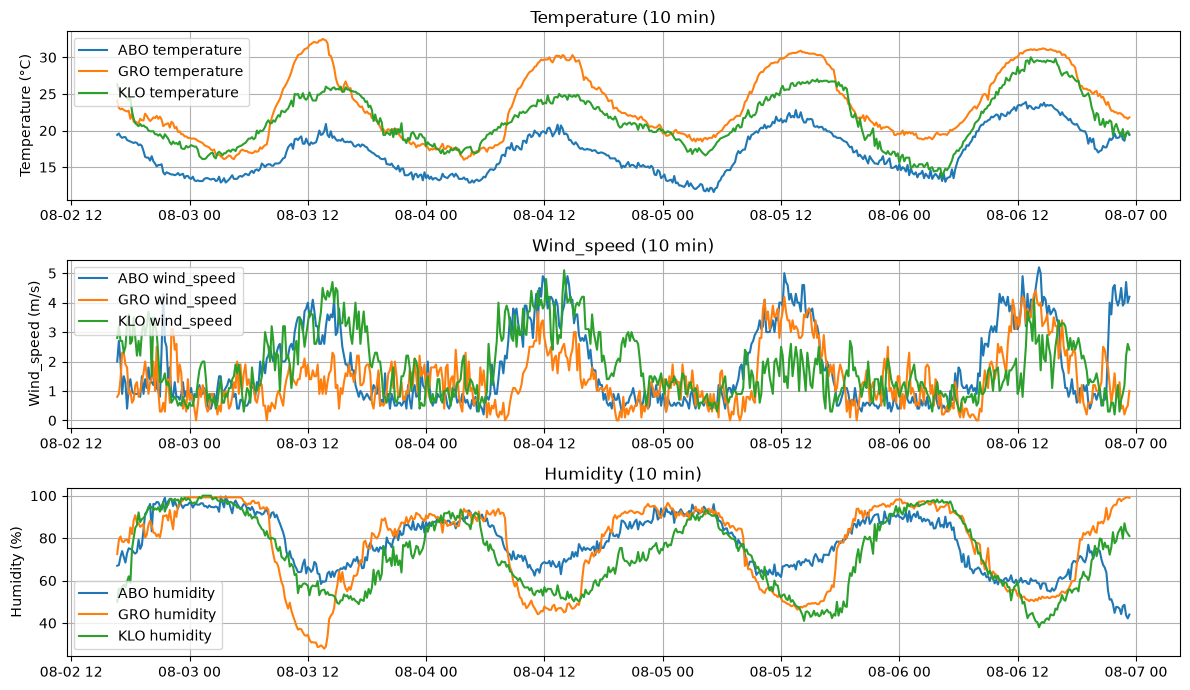

In [16]:
plot_weather_parameters(df, stations=["ABO", "GRO", "KLO"], parameters=["temperature", "wind_speed", "humidity"])

In [24]:
windows = dataset.get_windows(
    window_size=24,  # number of lookback time steps
    horizon_size=24,  # number of lead times to be predicted
    stations=["KLO", "ABO"],
    split="nwp_test",
    parameters=["temperature", "wind_u", "wind_v"],
    nwp_parameters=["temperature", "wind_u", "wind_v"],
    drop_extra_y_pars=False,
)

TypeError: open_group() got an unexpected keyword argument 'zarr_format'